# Cluster-background proof of concept: O(1) bright galaxies behind one cluster

**README.md Phase 7: "Cluster-background proof-of-concept scenario (O(1) bright galaxies)."**
Photometric weak lensing needs tens of thousands of background galaxy *shapes* stacked to beat
down shape noise. Kinematic lensing's whole premise (Blain 2002; Morales 2006; Huff et al. 2013)
is that a single galaxy's *resolved velocity field* gives a shear estimate competitive with a
shape measurement, so a cluster lensing signal can in principle be probed with a mere handful of
well-resolved background discs -- not a survey. This notebook is that proof of concept: place a
small number ($O(1)$, five here) of bright background discs at different projected radii and
azimuths around one foreground cluster, forward-model and fit each one independently through
KINO's real `IFU` pipeline, and check whether the recovered tangential shears trace the cluster's
predicted profile -- with a cross-shear ($g_\times$) null test, the standard real-analysis check
for a spurious signal.

Unlike `notebooks/10_sifs_forecast.ipynb`/`13_gmtifs_forecast.ipynb`/`14_manifest_gmacs_forecast.ipynb`,
this notebook is **not** another night/seeing-resolved observing-conditions sweep -- that ground is
already covered. It fixes one idealised, already-validated SIFS setup (`notebooks/data/
fisher_validation.json`'s `nested_sampling_cube` fiducial, reused via `scripts/
run_phase6_ensemble.py`'s `fiducial_ifu`) and focuses on the **multi-target cluster geometry**: the
2-D (radius + azimuth) SIS shear pattern, five independent pointings, and the recovered-vs-predicted
profile with its null test.

In [1]:
import dataclasses

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.constants import c as c_light
from astropy.cosmology import Planck18
from kino_style import AQUA, BLUE, INK2, ORANGE
from scipy.optimize import minimize, minimize_scalar

from kino.analysis.fisher import shear_fisher
from kino.analysis.forecast import narrowed_ifu
from kino.galaxy import DiscGalaxy
from kino.inference.likelihood import GALAXY_FIELDS, IFUCubeLikelihood
from kino.instruments.base import PSF
from kino.instruments.ifu import IFU
from kino.lensing import apply_shear

LINE = 6564.61 * u.AA  # Halpha, rest frame, vacuum -- same convention/value as
# scripts/run_phase6_ensemble.py and notebooks/04/10
Z_SOURCE = 0.06  # matches the already-validated fiducial_ifu() noise/window setup
M200 = 1e14 * u.Msun  # fiducial foreground cluster mass -- same "for now" placeholder
R_REF = 100 * u.kpc  # reference radius used to pick z_lens, as in notebook 11

print(f"M200 = {M200:.1e}, z_source = {Z_SOURCE}, reference radius = {R_REF}")

M200 = 1.0e+14 solMass, z_source = 0.06, reference radius = 100.0 kpc


## 1. The cluster: a singular isothermal sphere (SIS), in two dimensions

Notebook 11 (`11_goodman_forecast.ipynb`, Section 2) already derives a cluster's tangential-shear
*magnitude* vs. projected radius from an SIS model: the Evrard et al. (2008) mass-velocity
dispersion relation, then the standard SIS Einstein radius and $\gamma_t(\theta)=\theta_E/2\theta$.
This notebook needs the shear's full **vector** field, because the five background galaxies sit
at different azimuths $\phi$ around the cluster centre, not all along one axis.

For an axisymmetric lens with no B-mode, the standard weak-lensing decomposition
(Bartelmann & Schneider 2001, *Weak Gravitational Lensing*, review, eq. 3.17-ish) is
$\gamma_t = -\mathrm{Re}(\gamma\, e^{-2i\phi})$, $\gamma_\times = -\mathrm{Im}(\gamma\, e^{-2i\phi})$,
with $\phi$ the source's position angle relative to the lens centre. For a pure E-mode
($\gamma_\times=0$) this inverts to
$$g_1 = -\gamma_t\cos(2\phi), \qquad g_2 = -\gamma_t\sin(2\phi).$$

$\phi$ here must use **KINO's own reduced-shear phase convention**
(`kino/lensing/shear.py`'s module docstring): the standard math angle, counter-clockwise from the
$+x$ (East) axis -- *not* `DiscGalaxy.pa`'s East-of-North sense (`phi = 90 deg - pa`). Sanity check
below: at $\phi=0$ (galaxy due East of the cluster), the tangential direction is due North/South,
so $g_1$ must come out **negative** (compression along the radius, elongation tangentially) with
$g_2=0$; `tests/lensing/test_shear.py::test_circular_source_ellipticity_equals_g` is what pins the
sign of `apply_shear` that this depends on.

In [2]:
def sis_gamma_t(mass, z_lens, z_source, r_phys):
    """Tangential shear magnitude of an SIS cluster at projected physical radius r_phys,
    for a source at z_source (Evrard et al. 2008 M-sigma relation + the SIS lensing formula --
    see notebooks/11_goodman_forecast.ipynb, Section 2, for the full derivation)."""
    Ez = Planck18.efunc(z_lens)
    sigma_v = 1082.9 * u.km / u.s * (Ez * (mass / (1e15 * u.Msun))) ** 0.3361
    D_L = Planck18.angular_diameter_distance(z_lens)
    D_S = Planck18.angular_diameter_distance(z_source)
    D_LS = Planck18.angular_diameter_distance(z_lens, z_source)
    theta_E = (4 * np.pi * (sigma_v / c_light) ** 2 * (D_LS / D_S)).decompose() * u.rad
    theta = (r_phys / D_L).decompose() * u.rad
    return (theta_E.to(u.arcsec) / (2 * theta.to(u.arcsec))).decompose().value


def sis_shear_components(mass, z_lens, z_source, r_phys, phi_rad):
    """(g1, g2) of a pure-E-mode SIS tangential shear pattern at projected radius r_phys
    and azimuth phi_rad (standard math angle, ccw from +x/East -- see the markdown above)."""
    gamma_t = sis_gamma_t(mass, z_lens, z_source, r_phys)
    return -gamma_t * np.cos(2 * phi_rad), -gamma_t * np.sin(2 * phi_rad)


opt = minimize_scalar(
    lambda z: -sis_gamma_t(M200, z, Z_SOURCE, R_REF), bounds=(1e-3, Z_SOURCE - 1e-3),
    method="bounded",
)  # fmt: skip
Z_LENS = float(opt.x)
print(f"peak-efficiency z_lens at r={R_REF}: {Z_LENS:.3f}  (gamma_t there = {-opt.fun:.4f})")

g1_check, g2_check = sis_shear_components(M200, Z_LENS, Z_SOURCE, R_REF, 0.0)
print(f"sanity check at phi=0: (g1, g2) = ({g1_check:.4f}, {g2_check:.4f}) -- g1 must be < 0")
assert g1_check < 0 and abs(g2_check) < 1e-12

peak-efficiency z_lens at r=100.0 kpc: 0.029  (gamma_t there = 0.0112)
sanity check at phi=0: (g1, g2) = (-0.0112, -0.0000) -- g1 must be < 0


## 2. Five bright background discs around the cluster

Five illustrative pointings (not drawn from any real catalogue), spanning a range of projected
radii and azimuths so the recovered profile tests both the radial falloff and the tangential
*pattern* of the shear, not just its magnitude along one direction.

In [3]:
ifu0 = IFU.from_config("../kino/config/sifs.yaml")
ifu = narrowed_ifu(ifu0, LINE * (1 + Z_SOURCE), 500.0)
ifu = dataclasses.replace(
    ifu,
    psf=PSF(seeing_fwhm=1.0 * u.arcsec),
    detector=dataclasses.replace(ifu.detector, read_noise=3.0 * u.electron),
    sky_electron_rate=0.5 * u.electron / u.s,
)  # the same fiducial noise/window setup as scripts/run_phase6_ensemble.py's fiducial_ifu(),
# matching notebooks/data/fisher_validation.json's validated nested_sampling_cube entry

FLUX = 2e-13 * u.erg / u.s / u.cm**2  # one "bright" flux for all five targets

targets = [
    dict(r_phys=60 * u.kpc, phi_deg=10.0, r_e=1.2, inc=55.0, pa=20.0, v_flat=180.0),
    dict(r_phys=120 * u.kpc, phi_deg=80.0, r_e=1.0, inc=65.0, pa=100.0, v_flat=200.0),
    dict(r_phys=200 * u.kpc, phi_deg=150.0, r_e=1.5, inc=45.0, pa=160.0, v_flat=160.0),
    dict(r_phys=350 * u.kpc, phi_deg=220.0, r_e=1.3, inc=60.0, pa=50.0, v_flat=190.0),
    dict(r_phys=550 * u.kpc, phi_deg=300.0, r_e=1.1, inc=50.0, pa=130.0, v_flat=170.0),
]

print(f"{'r [kpc]':>8s} {'phi [deg]':>10s} {'g1_true':>9s} {'g2_true':>9s} {'gamma_t':>9s}")
for t in targets:
    phi_rad = np.deg2rad(t["phi_deg"])
    g1, g2 = sis_shear_components(M200, Z_LENS, Z_SOURCE, t["r_phys"], phi_rad)
    t["g1_true"], t["g2_true"] = g1, g2
    gt = sis_gamma_t(M200, Z_LENS, Z_SOURCE, t["r_phys"])
    print(f"{t['r_phys'].value:8.0f} {t['phi_deg']:10.0f} {g1:9.4f} {g2:9.4f} {gt:9.4f}")

 r [kpc]  phi [deg]   g1_true   g2_true   gamma_t
      60         10   -0.0175   -0.0064    0.0187
     120         80    0.0088   -0.0032    0.0093
     200        150   -0.0028    0.0049    0.0056
     350        220   -0.0006   -0.0032    0.0032
     550        300    0.0010    0.0018    0.0020


## 3. Observe and fit each target independently

Each target is its own single-pointing mock (one noisy realisation, seeded via a child of one
`SeedSequence` for reproducibility -- the same pattern `kino.analysis.injection` uses). The fit
holds every structural `DiscGalaxy` field at its (known) truth and frees only `(g1, g2)` --
exactly the idealisation `shear_fisher`'s `sigma_fixed` bounds, so the quoted error bar below is
that Fisher bound evaluated at each target's own truth point, not an assumption.

In [4]:
seeds = np.random.SeedSequence(15).spawn(len(targets))

for t, seed in zip(targets, seeds, strict=True):
    gal = DiscGalaxy(
        r_e=t["r_e"], inc=t["inc"], pa=t["pa"], v_flat=t["v_flat"], z=Z_SOURCE, sigma0=30.0
    )
    g_true = (t["g1_true"], t["g2_true"])
    rng = np.random.default_rng(seed)
    data = ifu.observe(apply_shear(gal, *g_true), line_flux=FLUX, line_wavelength=LINE, rng=rng)

    fixed = {f: getattr(gal, f) for f in GALAXY_FIELDS}
    lik = IFUCubeLikelihood(
        ifu=ifu, line_wavelength=LINE, data=data, fixed_galaxy_params=fixed, fixed_line_flux=FLUX
    )
    res = minimize(
        lambda p, lik=lik: -lik({"g1": p[0], "g2": p[1]}), x0=list(g_true), method="Nelder-Mead",
        options=dict(xatol=1e-4, fatol=1e-3, maxiter=300),
    )  # fmt: skip

    fr = shear_fisher(ifu, gal, line_flux=FLUX, line_wavelength=LINE, g=g_true)
    t["g1_rec"], t["g2_rec"] = float(res.x[0]), float(res.x[1])
    t["sigma_g1"], t["sigma_g2"] = fr.sigma_fixed
    t["median_spaxel_snr"] = fr.median_spaxel_snr

print(f"{'r [kpc]':>8s} {'g1_rec':>9s} {'g2_rec':>9s} {'sigma_g':>9s} {'med S/N':>8s}")
for t in targets:
    print(
        f"{t['r_phys'].value:8.0f} {t['g1_rec']:9.4f} {t['g2_rec']:9.4f} "
        f"{t['sigma_g1']:9.4f} {t['median_spaxel_snr']:8.1f}"
    )

 r [kpc]    g1_rec    g2_rec   sigma_g  med S/N
      60   -0.0172   -0.0057    0.0012     11.9
     120    0.0076   -0.0040    0.0012     13.7
     200   -0.0003    0.0061    0.0013     10.6
     350   -0.0002   -0.0025    0.0011     11.9
     550    0.0011    0.0013    0.0012     12.5


## 4. The tangential/cross profile, and a $g_\times$ null test

Project each target's true and recovered $(g_1, g_2)$ onto the tangential/cross basis at its own
azimuth: $g_t = -(g_1\cos 2\phi + g_2\sin 2\phi)$, $g_\times = -(g_2\cos 2\phi - g_1\sin 2\phi)$
(the inverse of Section 1's decomposition). By construction $g_{\times,\mathrm{true}}=0$
everywhere (a pure SIS E-mode field); the recovered $g_\times$ is a real null test -- a
significant nonzero value would flag a systematic (e.g. a PA convention error) rather than real
cluster shear. Propagating `sigma_g1`/`sigma_g2` into $\sigma_{g_t}$/$\sigma_{g_\times}$ below
drops their (generally small, unmeasured) covariance -- an approximation, not exact.

g_x pulls: [-0.45 -1.   -2.2   0.25 -0.22]  (expect O(1), no systematic trend)


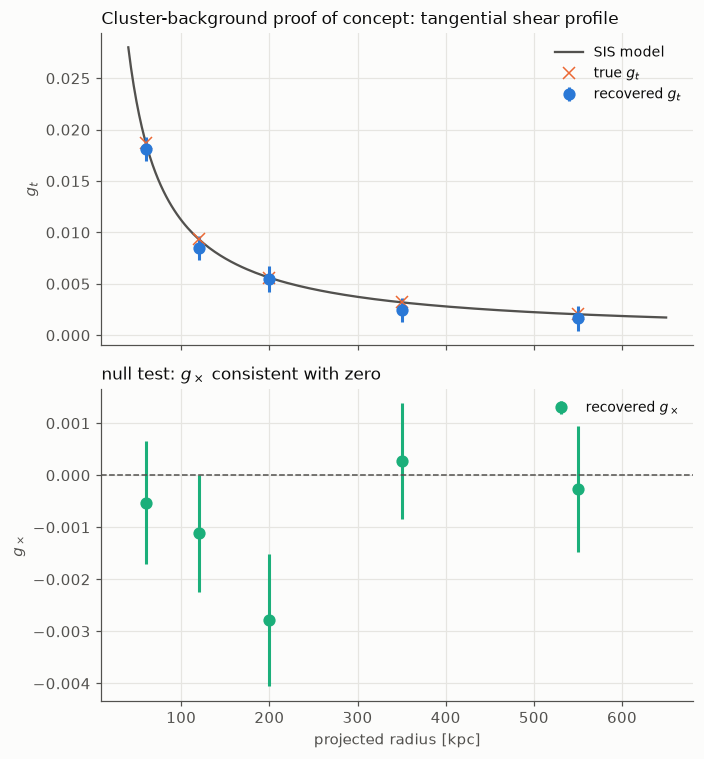

In [5]:
def project(g1, g2, phi_rad):
    c2, s2 = np.cos(2 * phi_rad), np.sin(2 * phi_rad)
    gt = -(g1 * c2 + g2 * s2)
    gx = -(g2 * c2 - g1 * s2)
    return gt, gx


for t in targets:
    phi_rad = np.deg2rad(t["phi_deg"])
    t["gt_true"], t["gx_true"] = project(t["g1_true"], t["g2_true"], phi_rad)
    t["gt_rec"], t["gx_rec"] = project(t["g1_rec"], t["g2_rec"], phi_rad)
    c2, s2 = np.cos(2 * phi_rad), np.sin(2 * phi_rad)
    t["sigma_gt"] = np.hypot(c2 * t["sigma_g1"], s2 * t["sigma_g2"])
    t["sigma_gx"] = np.hypot(s2 * t["sigma_g1"], c2 * t["sigma_g2"])

r_kpc = np.array([t["r_phys"].to_value(u.kpc) for t in targets])
gt_true = np.array([t["gt_true"] for t in targets])
gt_rec = np.array([t["gt_rec"] for t in targets])
gx_rec = np.array([t["gx_rec"] for t in targets])
sigma_gt = np.array([t["sigma_gt"] for t in targets])
sigma_gx = np.array([t["sigma_gx"] for t in targets])

r_smooth = np.linspace(40, 650, 200) * u.kpc
gt_model = np.array([sis_gamma_t(M200, Z_LENS, Z_SOURCE, r) for r in r_smooth])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True)
ax1.plot(r_smooth.to_value(u.kpc), gt_model, "-", color=INK2, lw=1.5, label="SIS model")
ax1.errorbar(r_kpc, gt_rec, yerr=sigma_gt, fmt="o", color=BLUE, label="recovered $g_t$")
ax1.plot(r_kpc, gt_true, "x", color=ORANGE, ms=8, label="true $g_t$")
ax1.set_ylabel(r"$g_t$")
ax1.set_title("Cluster-background proof of concept: tangential shear profile")
ax1.legend()

ax2.errorbar(r_kpc, gx_rec, yerr=sigma_gx, fmt="o", color=AQUA, label=r"recovered $g_\times$")
ax2.axhline(0.0, color=INK2, lw=1.0, ls="--")
ax2.set_xlabel("projected radius [kpc]")
ax2.set_ylabel(r"$g_\times$")
ax2.set_title(r"null test: $g_\times$ consistent with zero")
ax2.legend()
fig.tight_layout()

pull = (gx_rec - 0.0) / sigma_gx
print(f"g_x pulls: {np.round(pull, 2)}  (expect O(1), no systematic trend)")

## Known limitations

- **Synthetic placements.** The five targets' sky positions, sizes, inclinations, PAs and
  rotation velocities are illustrative and seeded for reproducibility, not drawn from any real
  catalogue or candidate list.
- **The cluster mass/redshift are fiducial placeholders**, exactly as flagged in
  `notebooks/11_goodman_forecast.ipynb`: $M_{200}=10^{14}\,M_\odot$ is "for now," and $z_\mathrm{lens}$
  is chosen to maximise the shear at one reference radius, not measured for a real cluster.
- **Idealised, fixed observing conditions.** Unlike notebooks 10/11/13/14, this notebook does not
  thread a real site/night/seeing sweep through the forecast -- it reuses one fixed, already-
  validated SIFS fiducial (`scripts/run_phase6_ensemble.py`'s `fiducial_ifu()`) so the five fits
  stay fast; that ground is covered elsewhere.
- **Each fit holds structural parameters at their true values** (`sigma_fixed`, not
  `sigma_marginal`) -- optimistic relative to a real fit with free inclination/PA/`v_flat`,
  exactly as `CLAUDE.md`/`kino.analysis.fisher` already document for every other forecast in
  this repo.
- **One noise realisation per target**, not an ensemble -- the recovered points and the $g_\times$
  pulls above are what this one seed happened to draw, not a bias/scatter characterisation (see
  `notebooks/data/phase6_ensemble.json`/`Research/KINO Phase 6 Ensemble Validation` for that).
- **$\sigma_{g_t}$/$\sigma_{g_\times}$ drop the $g_1$-$g_2$ covariance** in the tangential/cross
  projection -- an approximation, not an exact propagation.
- **Five galaxies is a proof of concept, not a measurement.** It demonstrates that KL's
  per-galaxy shear precision is good enough to trace a cluster profile with a handful of sources
  -- it does not claim this specific profile is detected at any particular significance.